### Integrationstechniken und Differentialgleichungen - Übungen

In diesem Notebook (Vertiefungskurs) geht es um **Integrationstechniken** und **Differentialgleichungen**.
Mit **partieller Integration** und **Substitution** findest du Stammfunktionen, die man nicht einfach „ablesen“ kann.
Danach löst du Differentialgleichungen: mit **Trennung der Variablen**, als **lineare** Gleichungen und als **Schwingungsgleichung**;
das **Richtungsfeld** zeigt, wie die Lösungen verlaufen.

`integrate()` und `dsolve()` liefern das Ergebnis sofort. Hier geht es aber um den **Rechenweg**: Du führst die Schritte einzeln mit sympy aus
und vergleichst am Ende mit dem fertigen Ergebnis.

Vorausgesetzt werden die Notebooks *Integrale* und *Wachstum* (`dsolve`).

Jeder Abschnitt beginnt mit kurzen Erklärungen und Beispielen. Führe die Beispiele aus und probiere sie ruhig ein wenig aus.
Danach folgen viele kleine Übungen. Unter den meisten Aufgaben steht das **erwartete Ergebnis**.

Unter den Aufgaben kannst du jeweils die Lösung aufklappen. Versuche es aber immer zuerst selbst!
Bei den Aufgaben „Was wird ausgegeben?“ gibt es keine Lösung zum Aufklappen: Dort führst du einfach die Zelle aus und vergleichst.

#### sympy laden

**Führe diese Zelle zuerst aus** (und nach jedem Neustart des Kernels wieder). Sie lädt sympy und matplotlib, schaltet die Formel-Ausgabe ein
und legt die reellen Variablen `x`, `u`, die Konstanten `C1`, `C2` und das Funktionssymbol `y` (für Differentialgleichungen) an.

In [ ]:
from sympy import *
init_printing()
import matplotlib.pyplot as plt
x, u = symbols('x u', real=True)
C1, C2 = symbols('C1 C2')
y = Function('y')

## 1. Partielle Integration

#### ∫ u · v' dx = u · v − ∫ u' · v dx

Die **partielle Integration** kommt aus der Produktregel. Man zerlegt den Integranden in einen Faktor u, der beim Ableiten einfacher wird,
und einen Faktor v', den man integrieren kann.

Beispiel ∫ x · eˣ dx: u = x (u' = 1), v' = eˣ (v = eˣ). Dann ist ∫ x · eˣ dx = x · eˣ − ∫ 1 · eˣ dx = (x − 1) · eˣ.

In [ ]:
uu = x
vs = exp(x)
v = integrate(vs, x)
F = uu * v - integrate(diff(uu, x) * v, x)
display(factor(F))
display(integrate(x * exp(x), x))
simplify(diff(F, x) - x * exp(x))

#### Aufgabe 1.1

Berechne ∫ x · sin(x) dx mit partieller Integration (u = x, v' = sin x) wie im Beispiel und vergleiche mit `integrate`.

**Erwartete Ausgabe:**

$\displaystyle - x \cos{\left(x \right)} + \sin{\left(x \right)}$

$\displaystyle - x \cos{\left(x \right)} + \sin{\left(x \right)}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
uu, vs = x, sin(x)
v = integrate(vs, x)
F = uu * v - integrate(diff(uu, x) * v, x)
display(F)
integrate(x * sin(x), x)
```

</details>

#### Aufgabe 1.2

Berechne ∫ x · e^(−x) dx mit partieller Integration.

**Erwartete Ausgabe:**

$\displaystyle - \left(x + 1\right) e^{- x}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
uu, vs = x, exp(-x)
v = integrate(vs, x)
F = uu * v - integrate(diff(uu, x) * v, x)
factor(F)
```

</details>

#### Aufgabe 1.3

Berechne ∫ ln(x) dx mit dem Trick ln(x) = 1 · ln(x): u = ln(x), v' = 1.

**Erwartete Ausgabe:**

$\displaystyle x \log{\left(x \right)} - x$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
uu, vs = log(x), 1
v = integrate(vs, x)
F = uu * v - integrate(diff(uu, x) * v, x)
F
```

</details>

#### Aufgabe 1.4

Berechne ∫ x · ln(x) dx (u = ln x, v' = x).

**Erwartete Ausgabe:**

$\displaystyle \frac{x^{2} \log{\left(x \right)}}{2} - \frac{x^{2}}{4}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
uu, vs = log(x), x
v = integrate(vs, x)
F = uu * v - integrate(diff(uu, x) * v, x)
expand(F)
```

</details>

#### Aufgabe 1.5

∫ x² · eˣ dx braucht **zweimal** partielle Integration. Gib zuerst u · v − ∫ u'·v **ohne** das letzte Integral auszurechnen aus
(`Integral(...)` statt `integrate`), dann das Endergebnis mit `integrate` (ausgeklammert).

**Erwartete Ausgabe:**

$\displaystyle x^{2} e^{x} - \int 2 x e^{x}\, dx$

$\displaystyle \left(x^{2} - 2 x + 2\right) e^{x}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
display(x**2 * exp(x) - Integral(2*x * exp(x), x))
factor(integrate(x**2 * exp(x), x))
```

</details>

#### Aufgabe 1.6

Berechne das bestimmte Integral ∫₀^π x · sin(x) dx: [u · v]₀^π − ∫₀^π u' · v dx.

**Erwartete Ausgabe:**

$\displaystyle \pi$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
uu, vs = x, sin(x)
v = integrate(vs, x)
(uu * v).subs(x, pi) - (uu * v).subs(x, 0) - integrate(diff(uu, x) * v, (x, 0, pi))
```

</details>

#### Aufgabe 1.7

**Phönix-Trick:** Bei I = ∫ eˣ · sin(x) dx kommt nach zweimaliger partieller Integration I wieder vor: I = eˣ sin x − eˣ cos x − I. Löse diese Gleichung nach I
(mit `solve(..., simplify=False)`, sonst schreibt sympy das Ergebnis mit einem verschobenen Kosinus) und vergleiche mit `integrate`.

**Erwartete Ausgabe:**

$\displaystyle \left[ \frac{e^{x} \sin{\left(x \right)}}{2} - \frac{e^{x} \cos{\left(x \right)}}{2}\right]$

$\displaystyle \frac{e^{x} \sin{\left(x \right)}}{2} - \frac{e^{x} \cos{\left(x \right)}}{2}$

In [ ]:
I_ = symbols('I_')
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
I_ = symbols('I_')
display(solve(Eq(I_, exp(x) * sin(x) - exp(x) * cos(x) - I_), I_, simplify=False))
integrate(exp(x) * sin(x), x)
```

</details>

#### Aufgabe 1.8

Prüfe das Ergebnis von ∫ x² · cos(x) dx durch Ableiten (`simplify` der Differenz).

**Erwartete Ausgabe:**

$\displaystyle x^{2} \sin{\left(x \right)} + 2 x \cos{\left(x \right)} - 2 \sin{\left(x \right)}$

$\displaystyle 0$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
F = integrate(x**2 * cos(x), x)
display(F)
simplify(diff(F, x) - x**2 * cos(x))
```

</details>

## 2. Integration durch Substitution

#### ∫ f(g(x)) · g'(x) dx = F(g(x))

Steht im Integranden eine verkettete Funktion **und** die Ableitung der inneren Funktion, ersetzt man die innere Funktion durch u = g(x).
Dann ist du = g'(x) dx, und das Integral wird einfacher.

Beispiel ∫ 2x · cos(x²) dx: u = x², du = 2x dx, also ∫ cos(u) du = sin(u) = sin(x²).

Mit sympy: Integrand durch g'(x) teilen, g(x) durch u ersetzen (`subs`), nach u integrieren, dann u = g(x) zurücksetzen.

In [ ]:
g = x**2
integrand = 2*x * cos(x**2)
in_u = simplify(integrand / diff(g, x)).subs(g, u)
display(in_u)
Fu = integrate(in_u, u)
display(Fu.subs(u, g))
integrate(integrand, x)

#### Aufgabe 2.1

Berechne ∫ 3x² · e^(x³) dx mit der Substitution u = x³ wie im Beispiel.

**Erwartete Ausgabe:**

$\displaystyle e^{u}$

$\displaystyle e^{x^{3}}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
g = x**3
in_u = simplify(3*x**2 * exp(x**3) / diff(g, x)).subs(g, u)
display(in_u)
integrate(in_u, u).subs(u, g)
```

</details>

#### Aufgabe 2.2

Berechne ∫ x · (x² + 1)⁵ dx mit u = x² + 1 (hier bleibt ein Faktor 1/2).

**Erwartete Ausgabe:**

$\displaystyle \frac{u^{5}}{2}$

$\displaystyle \frac{\left(x^{2} + 1\right)^{6}}{12}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
g = x**2 + 1
in_u = simplify(x * (x**2 + 1)**5 / diff(g, x)).subs(g, u)
display(in_u)
integrate(in_u, u).subs(u, g)
```

</details>

#### Aufgabe 2.3

Berechne ∫ cos(x) · sin³(x) dx mit u = sin(x).

**Erwartete Ausgabe:**

$\displaystyle u^{3}$

$\displaystyle \frac{\sin^{4}{\left(x \right)}}{4}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
g = sin(x)
in_u = simplify(cos(x) * sin(x)**3 / diff(g, x)).subs(g, u)
display(in_u)
integrate(in_u, u).subs(u, g)
```

</details>

#### Aufgabe 2.4

Berechne ∫ x/(x² + 4) dx mit u = x² + 4 (ein Logarithmus entsteht).

**Erwartete Ausgabe:**

$\displaystyle \frac{1}{2 u}$

$\displaystyle \frac{\log{\left(x^{2} + 4 \right)}}{2}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
g = x**2 + 4
in_u = simplify(x / (x**2 + 4) / diff(g, x)).subs(g, u)
display(in_u)
integrate(in_u, u).subs(u, g)
```

</details>

#### Aufgabe 2.5

**Logarithmische Integration:** ∫ g'(x)/g(x) dx = ln|g(x)|. Berechne ∫ (2x + 3)/(x² + 3x + 1) dx und ∫ tan(x) dx = ∫ sin(x)/cos(x) dx mit `integrate`.

**Erwartete Ausgabe:**

$\displaystyle \log{\left(x^{2} + 3 x + 1 \right)}$

$\displaystyle - \log{\left(\cos{\left(x \right)} \right)}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
display(integrate((2*x + 3) / (x**2 + 3*x + 1), x))
integrate(sin(x) / cos(x), x)
```

</details>

#### Aufgabe 2.6

Berechne ∫₀² x · e^(x²) dx mit Substitution: Die Grenzen werden mit u = x² zu 0 und 4. Rechne ∫₀⁴ (1/2) eᵘ du und vergleiche mit `integrate`.

**Erwartete Ausgabe:**

$\displaystyle - \frac{1}{2} + \frac{e^{4}}{2}$

$\displaystyle - \frac{1}{2} + \frac{e^{4}}{2}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
display(integrate(exp(u) / 2, (u, 0, 4)))
integrate(x * exp(x**2), (x, 0, 2))
```

</details>

#### Aufgabe 2.7

Prüfe durch Ableiten, dass F(x) = −(1/3)·(1 − x²)^(3/2) eine Stammfunktion von x · √(1 − x²) ist.

**Erwartete Ausgabe:**

$\displaystyle 0$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
F = -Rational(1, 3) * (1 - x**2)**Rational(3, 2)
simplify(diff(F, x) - x * sqrt(1 - x**2))
```

</details>

#### Aufgabe 2.8

**Fläche des Einheitskreises:** Berechne 4 · ∫₀¹ √(1 − x²) dx (Viertelkreis). Von Hand mit x = sin(u); hier mit `integrate`.

**Erwartete Ausgabe:**

$\displaystyle \pi$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
4 * integrate(sqrt(1 - x**2), (x, 0, 1))
```

</details>

#### Aufgabe 2.9

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```python
display(integrate(2*x * exp(x**2), x))
display(integrate(cos(3*x), x))
integrate(1 / (2*x + 1), x)
```

In [ ]:
display(integrate(2*x * exp(x**2), x))
display(integrate(cos(3*x), x))
integrate(1 / (2*x + 1), x)

## 3. Partialbruchzerlegung (Zusatz)

#### Brüche zerlegen, dann integrieren

Gebrochenrationale Funktionen zerlegt man in eine Summe einfacher Brüche (**Partialbrüche**), die man einzeln integrieren kann.
`apart(term, x)` zerlegt, z. B. (3x + 1)/(x² − 1) = 2/(x − 1) + 1/(x + 1).

Von Hand: Ansatz A/(x − 1) + B/(x + 1), mit dem Nenner (x − 1)(x + 1) multiplizieren: 3x + 1 = A(x + 1) + B(x − 1).
Setzt man die Nullstellen x = 1 und x = −1 ein, erhält man A und B.

In [ ]:
display(apart((3*x + 1) / (x**2 - 1), x))
A_, B_ = symbols('A_ B_')
gl = Eq(3*x + 1, A_ * (x + 1) + B_ * (x - 1))
display(solve([gl.subs(x, 1), gl.subs(x, -1)], [A_, B_]))
integrate((3*x + 1) / (x**2 - 1), x)

#### Aufgabe 3.1

Zerlege 1/(x² − 4) in Partialbrüche und integriere.

**Erwartete Ausgabe:**

$\displaystyle - \frac{1}{4 \left(x + 2\right)} + \frac{1}{4 \left(x - 2\right)}$

$\displaystyle \frac{\log{\left(x - 2 \right)}}{4} - \frac{\log{\left(x + 2 \right)}}{4}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
display(apart(1 / (x**2 - 4), x))
integrate(1 / (x**2 - 4), x)
```

</details>

#### Aufgabe 3.2

Zerlege (x + 5)/(x² + x − 2) in Partialbrüche und integriere.

**Erwartete Ausgabe:**

$\displaystyle - \frac{1}{x + 2} + \frac{2}{x - 1}$

$\displaystyle 2 \log{\left(x - 1 \right)} - \log{\left(x + 2 \right)}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
display(apart((x + 5) / (x**2 + x - 2), x))
integrate((x + 5) / (x**2 + x - 2), x)
```

</details>

#### Aufgabe 3.3

Zerlege x²/(x² − 1) (erst Polynomdivision, `apart` macht beides).

**Erwartete Ausgabe:**

$\displaystyle 1 - \frac{1}{2 \left(x + 1\right)} + \frac{1}{2 \left(x - 1\right)}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
apart(x**2 / (x**2 - 1), x)
```

</details>

#### Aufgabe 3.4

Berechne ∫₂³ 1/(x² − 1) dx genau und fasse die Logarithmen mit `logcombine` zusammen.

**Erwartete Ausgabe:**

$\displaystyle \log{\left(\frac{\sqrt{6}}{2} \right)}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
logcombine(integrate(1 / (x**2 - 1), (x, 2, 3)), force=True)
```

</details>

## 4. Differentialgleichungen und Richtungsfelder

#### y' = f(x, y)

Eine **Differentialgleichung 1. Ordnung** y' = f(x, y) gibt in jedem Punkt (x | y) die **Steigung** der Lösungskurve an.
Zeichnet man in vielen Punkten kleine Striche mit dieser Steigung, erhält man das **Richtungsfeld**; Lösungskurven folgen den Strichen.

Für das Zeichnen: Aus dem sympy-Term macht `lambdify((x, yy), term)` eine Python-Funktion mit zwei Eingaben. `plt.quiver(xs, ys, dx, dy)` zeichnet Pfeile
mit den Richtungen (dx, dy); für Striche mit gleicher Länge teilt man (1, m) durch √(1 + m²).

**Probe:** `checkodesol(dgl, loesung)` prüft eine Lösung, `dsolve(dgl, y(x))` löst die Gleichung.

In [ ]:
yy = symbols('yy', real=True)
steigung = lambdify((x, yy), x - yy)
xs, ys, dxs, dys = [], [], [], []
for i in range(-4, 5):
    for j in range(-4, 5):
        m = steigung(i / 2, j / 2)
        xs.append(i / 2)
        ys.append(j / 2)
        dxs.append(1 / (1 + m**2)**0.5)
        dys.append(m / (1 + m**2)**0.5)
plt.quiver(xs, ys, dxs, dys, angles='xy', pivot='mid')
loes = dsolve(Eq(y(x).diff(x), x - y(x)), y(x), ics={y(0): 1})
display(loes)
fl = lambdify(x, loes.rhs)
xx = [-2 + i / 20 for i in range(81)]
plt.plot(xx, [fl(w) for w in xx], 'r')
plt.ylim(-2, 2)
plt.show()

#### Aufgabe 4.1

Prüfe mit `checkodesol`, ob y = C1 · e^(x²/2) die Differentialgleichung y' = x · y löst.

**Erwartete Ausgabe:**

```
(True, 0)
```

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
checkodesol(Eq(y(x).diff(x), x * y(x)), Eq(y(x), C1 * exp(x**2 / 2)))
```

</details>

#### Aufgabe 4.2

Prüfe, welche der Funktionen y = x² + C1, y = 2x, y = x² die Differentialgleichung y' = 2x lösen (Liste der Ergebnisse von `checkodesol`).

**Erwartete Ausgabe:**

```
[(True, 0), (False, x - 1), (True, 0)]
```

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
dgl = Eq(y(x).diff(x), 2*x)
[checkodesol(dgl, Eq(y(x), w)) for w in [x**2 + C1, 2*x, x**2]]
```

</details>

#### Aufgabe 4.3

Löse y' = x · y allgemein und mit y(0) = 2.

**Erwartete Ausgabe:**

$\displaystyle y{\left(x \right)} = C_{1} e^{\frac{x^{2}}{2}}$

$\displaystyle y{\left(x \right)} = 2 e^{\frac{x^{2}}{2}}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
dgl = Eq(y(x).diff(x), x * y(x))
display(dsolve(dgl, y(x)))
dsolve(dgl, y(x), ics={y(0): 2})
```

</details>

#### Aufgabe 4.4

Zeichne das Richtungsfeld von y' = −x/y für −2 ≤ x, y ≤ 2 (Gitter mit Schritt 0,5, ohne die Punkte mit y = 0) wie im Beispiel.

**Erwartete Ausgabe:**



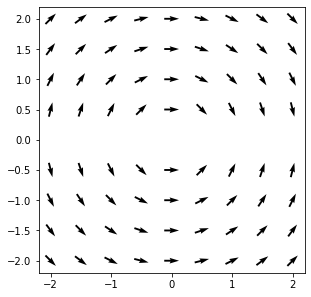

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
yy = symbols('yy', real=True)
steigung = lambdify((x, yy), -x / yy)
xs, ys, dxs, dys = [], [], [], []
for i in range(-4, 5):
    for j in range(-4, 5):
        if j != 0:
            m = steigung(i / 2, j / 2)
            xs.append(i / 2)
            ys.append(j / 2)
            dxs.append(1 / (1 + m**2)**0.5)
            dys.append(m / (1 + m**2)**0.5)
plt.quiver(xs, ys, dxs, dys, angles='xy', pivot='mid')
plt.gca().set_aspect('equal')
plt.show()
```

</details>

#### Aufgabe 4.5

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```python
dgl = Eq(y(x).diff(x), 3)
display(dsolve(dgl, y(x)))
dsolve(dgl, y(x), ics={y(0): 5})
```

In [ ]:
dgl = Eq(y(x).diff(x), 3)
display(dsolve(dgl, y(x)))
dsolve(dgl, y(x), ics={y(0): 5})

## 5. Trennung der Variablen

#### y' = g(x) · h(y)

Lässt sich die rechte Seite als Produkt g(x) · h(y) schreiben, trennt man die Variablen:

dy / h(y) = g(x) dx, also ∫ 1/h(y) dy = ∫ g(x) dx + C

Dann löst man nach y auf. Beispiel y' = x · y: ∫ 1/y dy = ∫ x dx ⟹ ln|y| = x²/2 + C ⟹ y = C1 · e^(x²/2).

In [ ]:
yv = symbols('yv', positive=True)
links = integrate(1 / yv, yv)
rechts = integrate(x, x) + C1
display(Eq(links, rechts))
display(solve(Eq(links, rechts), yv))
dsolve(Eq(y(x).diff(x), x * y(x)), y(x))

#### Aufgabe 5.1

Löse y' = y² · x mit Trennung der Variablen: Gib die Gleichung ∫ 1/y² dy = ∫ x dx + C1 und ihre Lösung nach y aus. Vergleiche mit `dsolve`.

**Erwartete Ausgabe:**

$\displaystyle - \frac{1}{yv} = C_{1} + \frac{x^{2}}{2}$

$\displaystyle \left[ - \frac{2}{2 C_{1} + x^{2}}\right]$

$\displaystyle y{\left(x \right)} = - \frac{2}{C_{1} + x^{2}}$

In [ ]:
yv = symbols('yv', positive=True)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
yv = symbols('yv', positive=True)
gl = Eq(integrate(1 / yv**2, yv), integrate(x, x) + C1)
display(gl)
display(solve(gl, yv))
dsolve(Eq(y(x).diff(x), y(x)**2 * x), y(x))
```

</details>

#### Aufgabe 5.2

Löse y' = e^(−y) · 2x mit Trennung der Variablen (∫ eʸ dy = ∫ 2x dx + C1) und gib y aus.

**Erwartete Ausgabe:**

$\displaystyle e^{yv} = C_{1} + x^{2}$

$\displaystyle \left[ \log{\left(C_{1} + x^{2} \right)}\right]$

In [ ]:
yv = symbols('yv', positive=True)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
yv = symbols('yv', positive=True)
gl = Eq(integrate(exp(yv), yv), integrate(2*x, x) + C1)
display(gl)
solve(gl, yv)
```

</details>

#### Aufgabe 5.3

Löse das Anfangswertproblem y' = x/y, y(0) = 2 mit `dsolve`.

**Erwartete Ausgabe:**

$\displaystyle y{\left(x \right)} = \sqrt{x^{2} + 4}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
dsolve(Eq(y(x).diff(x), x / y(x)), y(x), ics={y(0): 2})
```

</details>

#### Aufgabe 5.4

Löse das Anfangswertproblem y' = (1 + y²) mit y(0) = 0 (Lösung mit Tangens).

**Erwartete Ausgabe:**

$\displaystyle y{\left(x \right)} = \tan{\left(x \right)}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
dsolve(Eq(y(x).diff(x), 1 + y(x)**2), y(x), ics={y(0): 0})
```

</details>

#### Aufgabe 5.5

**Abkühlung (allgemein):** T' = −k · (T − 20). Löse mit `dsolve` für ein positives k und T(0) = 90.

**Erwartete Ausgabe:**

$\displaystyle y{\left(x \right)} = 20 + 70 e^{- k x}$

In [ ]:
k = symbols('k', positive=True)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
k = symbols('k', positive=True)
dsolve(Eq(y(x).diff(x), -k * (y(x) - 20)), y(x), ics={y(0): 90})
```

</details>

## 6. Lineare Differentialgleichungen 1. Ordnung

#### y' + a · y = b(x)

Eine **lineare** DGL hat die Form y' + a(x) · y = b(x). Ihre Lösung ist die allgemeine Lösung der **homogenen** Gleichung y' + a·y = 0
plus eine **spezielle** Lösung der ganzen Gleichung. Beispiel y' + y = x: homogen y = C1 · e⁻ˣ, speziell y = x − 1 (durch Einsetzen prüfen).

In [ ]:
dgl = Eq(y(x).diff(x) + y(x), x)
display(dsolve(Eq(y(x).diff(x) + y(x), 0), y(x)))
display(checkodesol(dgl, Eq(y(x), x - 1)))
dsolve(dgl, y(x))

#### Aufgabe 6.1

Löse y' − 2y = 4 allgemein und mit y(0) = 1.

**Erwartete Ausgabe:**

$\displaystyle y{\left(x \right)} = C_{1} e^{2 x} - 2$

$\displaystyle y{\left(x \right)} = 3 e^{2 x} - 2$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
dgl = Eq(y(x).diff(x) - 2 * y(x), 4)
display(dsolve(dgl, y(x)))
dsolve(dgl, y(x), ics={y(0): 1})
```

</details>

#### Aufgabe 6.2

Löse y' + y = eˣ und prüfe die spezielle Lösung y = eˣ/2 mit `checkodesol`.

**Erwartete Ausgabe:**

$\displaystyle y{\left(x \right)} = C_{1} e^{- x} + \frac{e^{x}}{2}$

```
(True, 0)
```

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
dgl = Eq(y(x).diff(x) + y(x), exp(x))
display(dsolve(dgl, y(x)))
checkodesol(dgl, Eq(y(x), exp(x) / 2))
```

</details>

#### Aufgabe 6.3

Löse y' + 2y = sin(x) allgemein.

**Erwartete Ausgabe:**

$\displaystyle y{\left(x \right)} = C_{1} e^{- 2 x} + \frac{2 \sin{\left(x \right)}}{5} - \frac{\cos{\left(x \right)}}{5}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
dsolve(Eq(y(x).diff(x) + 2 * y(x), sin(x)), y(x))
```

</details>

#### Aufgabe 6.4

**Fallschirm:** Die Geschwindigkeit v(t) beim Fall mit Luftwiderstand erfüllt v' = 9,81 − 0,2·v (Zahlen als `Rational`), v(0) = 0. Löse die DGL
(mit x als Zeit) und gib die Grenzgeschwindigkeit (x → ∞) aus.

**Erwartete Ausgabe:**

$\displaystyle y{\left(x \right)} = \frac{981}{20} - \frac{981 e^{- \frac{x}{5}}}{20}$

$\displaystyle \frac{981}{20}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
l = dsolve(Eq(y(x).diff(x), Rational(981, 100) - Rational(1, 5) * y(x)), y(x), ics={y(0): 0})
display(l)
limit(l.rhs, x, oo)
```

</details>

## 7. Schwingungen: Differentialgleichungen 2. Ordnung

#### y'' = −ω² · y

Eine Feder (ohne Reibung) erfüllt y'' = −ω² · y: Die Beschleunigung ist der Auslenkung entgegengesetzt. Die Lösungen sind
**Schwingungen** y = C1 · sin(ωx) + C2 · cos(ωx). Für eine eindeutige Lösung braucht man **zwei** Anfangswerte: y(0) und y'(0).
In sympy: `ics={y(0): 1, y(x).diff(x).subs(x, 0): 0}`.

Mit Reibung (gedämpfte Schwingung) kommt ein Term mit y' dazu, z. B. y'' + 2y' + 5y = 0; die Lösungen enthalten dann e^(−x).

In [ ]:
dgl = Eq(y(x).diff(x, 2), -4 * y(x))
display(dsolve(dgl, y(x)))
l = dsolve(dgl, y(x), ics={y(0): 1, y(x).diff(x).subs(x, 0): 0})
display(l)
d = dsolve(Eq(y(x).diff(x, 2) + Rational(1, 2) * y(x).diff(x) + 4 * y(x), 0), y(x), ics={y(0): 1, y(x).diff(x).subs(x, 0): 0})
plot(l.rhs, d.rhs, (x, 0, 10), legend=True);

#### Aufgabe 7.1

Löse y'' = −9y allgemein.

**Erwartete Ausgabe:**

$\displaystyle y{\left(x \right)} = C_{1} \sin{\left(3 x \right)} + C_{2} \cos{\left(3 x \right)}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
dsolve(Eq(y(x).diff(x, 2), -9 * y(x)), y(x))
```

</details>

#### Aufgabe 7.2

Löse y'' = −9y mit y(0) = 0 und y'(0) = 6.

**Erwartete Ausgabe:**

$\displaystyle y{\left(x \right)} = 2 \sin{\left(3 x \right)}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
dsolve(Eq(y(x).diff(x, 2), -9 * y(x)), y(x), ics={y(0): 0, y(x).diff(x).subs(x, 0): 6})
```

</details>

#### Aufgabe 7.3

Prüfe mit `checkodesol`, dass y = 3 · cos(2x) + sin(2x) die Gleichung y'' + 4y = 0 löst.

**Erwartete Ausgabe:**

```
(True, 0)
```

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
checkodesol(Eq(y(x).diff(x, 2) + 4 * y(x), 0), Eq(y(x), 3 * cos(2*x) + sin(2*x)))
```

</details>

#### Aufgabe 7.4

Löse die gedämpfte Schwingung y'' + 2y' + 5y = 0 mit y(0) = 1, y'(0) = −1.

**Erwartete Ausgabe:**

$\displaystyle y{\left(x \right)} = e^{- x} \cos{\left(2 x \right)}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
dsolve(Eq(y(x).diff(x, 2) + 2 * y(x).diff(x) + 5 * y(x), 0), y(x), ics={y(0): 1, y(x).diff(x).subs(x, 0): -1})
```

</details>

#### Aufgabe 7.5

Löse y'' − y = 0 allgemein (keine Schwingung, sondern e-Funktionen).

**Erwartete Ausgabe:**

$\displaystyle y{\left(x \right)} = C_{1} e^{- x} + C_{2} e^{x}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
dsolve(Eq(y(x).diff(x, 2) - y(x), 0), y(x))
```

</details>

#### Aufgabe 7.6

Zeichne die Lösung von y'' + 0,3·y' + y = 0 mit y(0) = 2, y'(0) = 0 für 0 ≤ x ≤ 30 (0,3 als `Rational`).

**Erwartete Ausgabe:**



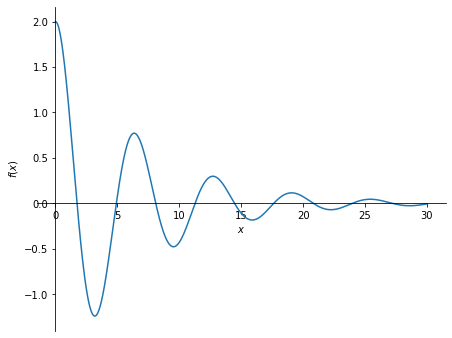

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
l = dsolve(Eq(y(x).diff(x, 2) + Rational(3, 10) * y(x).diff(x) + y(x), 0), y(x), ics={y(0): 2, y(x).diff(x).subs(x, 0): 0})
plot(l.rhs, (x, 0, 30));
```

</details>

## 8. Gemischte Übungen

#### Aufgabe 8.1

Berechne ∫ x³ · e^(x²) dx mit sympy und prüfe das Ergebnis durch Ableiten. (Von Hand: erst u = x², dann partiell.)

**Erwartete Ausgabe:**

$\displaystyle \frac{\left(x^{2} - 1\right) e^{x^{2}}}{2}$

$\displaystyle 0$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
F = integrate(x**3 * exp(x**2), x)
display(F)
simplify(diff(F, x) - x**3 * exp(x**2))
```

</details>

#### Aufgabe 8.2

Berechne ∫₁^e x² · ln(x) dx genau.

**Erwartete Ausgabe:**

$\displaystyle \frac{1}{9} + \frac{2 e^{3}}{9}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
integrate(x**2 * log(x), (x, 1, E))
```

</details>

#### Aufgabe 8.3

**Logistisches Wachstum:** Löse y' = y · (1 − y) mit y(0) = 1/2 mit `dsolve` und gib den Grenzwert für x → ∞ aus.

**Erwartete Ausgabe:**

$\displaystyle y{\left(x \right)} = \frac{1}{1 + e^{- x}}$

$\displaystyle 1$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
l = dsolve(Eq(y(x).diff(x), y(x) * (1 - y(x))), y(x), ics={y(0): Rational(1, 2)})
display(l)
limit(l.rhs, x, oo)
```

</details>

#### Aufgabe 8.4

Eine Kurve geht durch (0 | 1), und in jedem Punkt ist ihre Steigung gleich der Summe der Koordinaten (y' = x + y). Bestimme die Kurve.

**Erwartete Ausgabe:**

$\displaystyle y{\left(x \right)} = - x + 2 e^{x} - 1$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
dsolve(Eq(y(x).diff(x), x + y(x)), y(x), ics={y(0): 1})
```

</details>